# 04 · RQ4: Which Model Should a Company Choose? (Recommendation Engine + Backtest)
**Project:** Classifying the 2026 LLM API Market · ICT324 · Team Straw Hats · CRISP-DM phase: *Modeling (decision algorithm) + Evaluation*

### Research question and hypothesis
> **RQ4:** Which model should a company choose for a given task, requirements and budget, now and in the near future?
>
> **H4:** In a backtest, models picked by the decision algorithm give **better value** than the rules **"pick the cheapest"** and **"pick the top benchmark"**.

This notebook **tests** H4. The decision rule for H4 is written down in Step 1 *before* any result is computed, and the verdict in the last step is computed from the numbers, not written by hand.

### What "better value" means here (team decision, 25 Oct 2026)
**Value = the task score a company actually gets while staying under its budget.** A pick that has become **too expensive** for the budget, or has **disappeared** from the market, by the evaluation date gives the company nothing, so it scores **0**.

**Price = the cheapest provider** for that model (min across providers), because that is what a buyer can actually pay. RQ1 used the median for tiering, so the tier labels shown here are only descriptive.

### The decision algorithm (from the proposal)
```
input: task, requirements, monthly usage (input/output tokens), monthly budget
  1. filter by task capability       (has a score on the task's benchmarks; vision / tools / JSON if needed)
  2. filter by requirements          (min context, open-weight only, excluded labs, min score, released within N months)
  3. filter by budget                (monthly tokens × price ≤ budget)
  4. rank by value score             (task score ÷ monthly cost)
  5. future adjustment               (falling price trend → rank up; rising → rank down / drop if close to budget)
  6. return top 3 with tier and price trend
```

### Method in one picture
```
clean data (00) + tiers (01) [+ trends (03, when available)]
  → map benchmark-side models to price-history series (name normalisation)
  → weekly cheapest-provider cost per model and usage profile
  → task scores (percentile per test, averaged, as in RQ1)
  → ENGINE  (pure functions with an `as_of` week)  → demo: "which model now?"
  → BACKTEST: decide at cutoff C (data ≤ C only)  → score picks at 2026-09-28
        engine vs cheapest vs top-benchmark vs random vs hindsight-best (+ engine variants)
  → paired statistics  → H4 verdict
```

### How to run in Google Colab
Run the cells in order. The setup cell asks you to upload `clean_models.csv`, `clean_benchmarks.csv`, `clean_price_history.csv`, `clean_catalog.csv` (notebook 00) and `rq1_tiers.csv` (notebook 01). If `rq3_trends.csv` (notebook 03, RQ3) exists, upload it too and the engine uses it. Otherwise a simple placeholder trend rule is used (Step 5). The whole notebook runs in about a minute.

## Step 1 · Setup and pre-registered settings
All design choices that could change the answer are fixed **here**, before any result is seen:
- **Cutoffs** (decision dates). The **primary** cutoff is **2025-12-29**, which matches the proposal's "choose with 2025 data, check value in 2026". Two **secondary** rolling cutoffs (2026-03-30, 2026-06-29) add reasoning and vision tasks, which have no benchmark data before 2026. Their horizon is shorter (3–6 months).
- **Evaluation week:** **2026-09-28**, the last week of price history.
- **Primary H4 setting:** cutoff 2025-12-29, task *coding*, *lenient* benchmark mode (explained in Step 4).
- **H4 rule:** SUPPORTED if, in the primary setting, the engine's mean achieved score is higher than **both** "cheapest" and "top benchmark", with a paired Wilcoxon test p < 0.05 for **each**. PARTIAL if this holds against only one, and NOT supported otherwise.
- **Engine for H4** = the proposal's value-ranked algorithm (Step 6). A "score-first" variant is reported for comparison only.

In [1]:
import os, sys, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 40)
sns.set_theme(style="whitegrid")
SEED = 42

CUTOFFS = ["2025-12-29", "2026-03-30", "2026-06-29"]
PRIMARY = {"cutoff": "2025-12-29", "task": "coding", "mode": "lenient"}
EVAL_WEEK = "2026-09-28"
TREND_LOOKBACK_WEEKS = 12        # placeholder trend: price change over the last 12 weeks
TREND_THRESHOLD = 0.05           # ±5 % = falling / rising
TREND_ALPHA = 0.25               # step 5: falling ×1.25, rising ×0.75
RISING_DROP_SHARE = 0.90         # step 5: drop rising models already using ≥90 % of the budget
MIN_MODELS_PER_TEST = 5          # same rule as RQ1

IN_COLAB = "google.colab" in sys.modules
NEED = ["clean_models.csv", "clean_benchmarks.csv", "clean_price_history.csv",
        "clean_catalog.csv", "rq1_tiers.csv"]
if IN_COLAB:
    from google.colab import files
    DATA_DIR = OUT_DIR = FIG_DIR = "."
    if not all(os.path.exists(f) for f in NEED):
        print("Upload:", ", ".join(NEED), "(+ rq3_trends.csv if you have it)")
        files.upload()
else:
    DATA_DIR = OUT_DIR = "../data/processed"
    FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

models = pd.read_csv(os.path.join(DATA_DIR, "clean_models.csv"))
bench = pd.read_csv(os.path.join(DATA_DIR, "clean_benchmarks.csv"))
hist = pd.read_csv(os.path.join(DATA_DIR, "clean_price_history.csv"))
catalog = pd.read_csv(os.path.join(DATA_DIR, "clean_catalog.csv"))
tiers = pd.read_csv(os.path.join(DATA_DIR, "rq1_tiers.csv"))
TRENDS_FILE = os.path.join(DATA_DIR, "rq3_trends.csv")
for name, d in [("models", models), ("benchmarks", bench), ("price history", hist),
                ("catalog", catalog), ("tiers", tiers)]:
    print(f"{name:14s} {d.shape}")
assert all(w in set(hist.week_start) for w in CUTOFFS + [EVAL_WEEK]), "cutoff week missing"

models         (411, 33)
benchmarks     (977, 16)
price history  (162072, 15)
catalog        (2803, 33)
tiers          (144, 13)


## Step 2 · Link each benchmarked model to its price-history series
The two Kaggle datasets share **no key**. Benchmark-side models look like `anthropic/claude-sonnet-4-0`, while price-history ids look like `anthropic.claude-sonnet-4-20250514-v1:0` (AWS Bedrock), `openrouter/qwen/qwen3.8-flash`, and so on. We build one **normalised key** per name:
1. take the last path segment (`openrouter/qwen/qwen3.8-flash` → `qwen3.8-flash`);
2. remove cloud-region and vendor prefixes (`apac.`, `us.`, `anthropic.`, `meta.` …), version tails (`:0`, `-v1`) and 8-digit date stamps (`-20250514`);
3. lower-case and keep only letters and digits (`qwen3.8-flash` → `qwen38flash`).

A benchmark model matches a price-history row if its id **or** its display name gives the same key. A small **manual alias** list fixes known naming differences, and every alias is printed. Models that stay unmatched are listed, not hidden. An assertion guarantees that **no price series is linked to two benchmark models**, so no price is counted twice.

Only models that have **both** a valid price and at least one benchmark score can be recommended, because the engine needs a score to rank by.

In [2]:
def norm_key(s):
    s = str(s).lower().split("/")[-1]
    s = re.sub(r"^(apac|us|eu|au|jp|global)\.", "", s)
    s = re.sub(r"^(anthropic|meta|mistral|amazon|cohere|ai21|deepseek|qwen|openai|google|"
               r"moonshotai|minimax|zai|xai)\.", "", s)
    s = re.sub(r":.*$", "", s); s = re.sub(r"-v\d+$", "", s); s = re.sub(r"-20\d{6}$", "", s)
    return re.sub(r"[^a-z0-9]", "", s)

# manual fixes go here as {benchmark model_id: price key}. claude-sonnet-4-0 ("latest") is NOT aliased:
# it duplicates anthropic/claude-sonnet-4-20250514, which already owns the "claudesonnet4" key.
ALIASES = {}

cand = models[models.has_valid_price & models.model_id.isin(bench.model_id)].copy()
hist["key_id"], hist["key_name"] = hist.model_id.map(norm_key), hist.model_name.map(norm_key)
hist_keys = set(hist.key_id) | set(hist.key_name)
rows = []
for _, r in cand.iterrows():
    keys = {ALIASES.get(r.model_id, norm_key(r.model_id)), norm_key(r.model_name)}
    hit = sorted(k for k in keys if k in hist_keys)
    rows.append({"model_id": r.model_id, "model_name": r.model_name, "keys_matched": ",".join(hit),
                 "alias_used": r.model_id in ALIASES, "matched": bool(hit)})
mapping = pd.DataFrame(rows)
key2model = {}
for _, r in mapping[mapping.matched].iterrows():
    for k in r.keys_matched.split(","):
        key2model.setdefault(k, set()).add(r.model_id)
clash = {k: v for k, v in key2model.items() if len(v) > 1}
assert not clash, f"one price key maps to several models: {clash}"
key2model = {k: next(iter(v)) for k, v in key2model.items()}

hist["bm_model_id"] = hist.key_id.map(key2model).fillna(hist.key_name.map(key2model))
n_series = hist[hist.bm_model_id.notna()].groupby("bm_model_id").model_id.nunique()
mapping["n_price_series"] = mapping.model_id.map(n_series).fillna(0).astype(int)
print(f"priced + benchmarked models: {len(mapping)} | matched to price history: "
      f"{mapping.matched.sum()} ({mapping.matched.mean():.1%})")
print("aliases used:", ALIASES)
print("\nunmatched (kept visible, cannot be recommended):")
print(mapping.loc[~mapping.matched, ["model_id", "model_name"]].to_string(index=False))
print("\naudit sample: benchmark model → price-history ids it was linked to")
audit = (hist[hist.bm_model_id.notna()].groupby("bm_model_id").model_id
         .apply(lambda s: ", ".join(sorted(set(s))[:3])).rename("example_price_ids"))
print(audit.sample(8, random_state=SEED).to_string())

priced + benchmarked models: 147 | matched to price history: 143 (97.3%)
aliases used: {}

unmatched (kept visible, cannot be recommended):
                   model_id               model_name
 alibaba/qwen3.8-flash-next       Qwen3.8 Flash Next
alibaba/qwen3.8-max-preview      Qwen3.8 Max Preview
stepfun/step-3.5-flash-2603      Step 3.5 Flash 2603
anthropic/claude-sonnet-4-0 Claude Sonnet 4 (latest)

audit sample: benchmark model → price-history ids it was linked to
bm_model_id
perplexity/sonar-pro                openrouter/perplexity/sonar-pro, per...
anthropic/claude-opus-4-20250514    anthropic.claude-opus-4-20250514-v1:...
nvidia/nemotron-3.5-lightning       nebius/nvidia/Nemotron-3_5-Lightning...
openai/gpt-5.2-codex                azure/eu/gpt-5.2-codex, azure/gpt-5....
meta/muse-glimmer-30b               deepinfra/meta-models/Muse-Glimmer-3...
alibaba/qwen3.8-27b                 cerebras/qwen-3.8-27b, deepinfra/Qwe...
xiaomi/mimo-v2.6-pro                openrouter/xiaomi/mimo-

**Reading the result:** almost all priced, benchmarked models are linked. The unmatched ones are genuinely different models in the price data (a "preview", a "next" build, a dated variant), so linking them to the nearest name would be wrong. `claude-sonnet-4-0` ("latest") is a duplicate entry of `claude-sonnet-4-20250514`, which is linked. Scan the audit sample to check that each link points to the same model sold by different providers.

## Step 3 · Monthly cost per model, per week, using the cheapest provider
A company pays per token. For a given **usage profile** (input + output tokens per month), the monthly cost through one provider is

$$\text{cost} = \text{input tokens (M)} \times \text{input price} + \text{output tokens (M)} \times \text{output price}$$

and the model's cost is the **minimum over all providers** that sell it that week. We compute this per usage profile, because input/output price ratios differ between providers.

Decisions:
- **Zero-price rows are removed.** These are free tiers, which are rate-limited or promotional and not a realistic option for a company's production workload.
- A model is **available** in week *W* if at least one provider lists a non-zero price for it in *W*.

In [3]:
USAGE = {"small (10M in / 2M out)": (10, 2),
         "medium (100M in / 20M out)": (100, 20),
         "large (1B in / 200M out)": (1000, 200)}

h = hist[hist.bm_model_id.notna()].copy()
n0 = len(h)
h = h[(h.input_price_per_1m_tokens > 0) & (h.output_price_per_1m_tokens > 0)]
print(f"linked price rows: {n0:,} → after removing free / zero-price rows: {len(h):,}")
for u, (i, o) in USAGE.items():
    h[u] = i * h.input_price_per_1m_tokens + o * h.output_price_per_1m_tokens
h["blended"] = (3 * h.input_price_per_1m_tokens + h.output_price_per_1m_tokens) / 4   # 3:1 as in RQ1
COST = h.groupby(["bm_model_id", "week_start"])[list(USAGE) + ["blended"]].min()   # cheapest provider

def cost_at(week, usage):
    """Series model_id -> cheapest monthly cost in `week` for `usage` (missing = not available)."""
    try:
        return COST.xs(week, level="week_start")[usage]
    except KeyError:
        return pd.Series(dtype=float)

avail = {w: set(cost_at(w, list(USAGE)[0]).index) for w in CUTOFFS + [EVAL_WEEK]}
print({w: len(s) for w, s in avail.items()}, "models available per week")
print(COST.xs(EVAL_WEEK, level="week_start").describe().round(2).to_string())

linked price rows: 29,234 → after removing free / zero-price rows: 28,931
{'2025-12-29': 60, '2026-03-30': 77, '2026-06-29': 99, '2026-09-28': 142} models available per week
       small (10M in / 2M out)  medium (100M in / 20M out)  large (1B in / 200M out)  blended
count                   142.00                      142.00                    142.00   142.00
mean                     32.37                      323.75                   3237.45     3.19
std                      68.29                      682.92                   6829.22     6.65
min                       0.46                        4.55                     45.50     0.05
25%                       3.74                       37.38                    373.75     0.37
50%                       9.95                       99.50                    995.00     0.96
75%                      29.70                      297.00                   2970.00     2.95
max                     420.00                     4200.00                

## Step 4 · Task scores: which model is good at *this* task?
The engine ranks by a **task-specific** score, so each task needs its own benchmarks. The mapping below was chosen from **coverage**: benchmarks with enough priced models.

| Task | Benchmarks |
|---|---|
| coding | SWE-Bench Pro, SWE-Bench Verified, Aider Polyglot, Terminal-Bench (incl. Hard / 2.0), SciCode, LiveCodeBench |
| reasoning | Humanity's Last Exam, GPQA Diamond, AIME |
| vision | MMMU Pro, MathVision (and the model must accept image input) |

Raw scores use different units, so, **as in RQ1**, each model gets a **percentile within each test** (0 = worst, 1 = best, among the models available at the decision date), and the task score is the **mean** over its tests. A test is used only if it covers ≥ 5 models in that pool.

**Two information modes:**
- **Lenient:** all benchmark results are used, even those published after the decision date. Assumption: a model's ability does not change, only our knowledge of it does.
- **Strict:** only results with a `reported_date` on or before the decision date. This is the honest "what could a company know at that time" view, but 47% of results have no date and are therefore excluded.

The **engine and baselines** decide with their mode's scores. The **outcome** is always judged with the **lenient** score, our best estimate of the model's true quality.

In [4]:
TASK_BENCH = {
    "coding": ["SWE-Bench Pro", "SWE-Bench Verified", "Aider Polyglot", "Terminal-Bench",
               "Terminal-Bench Hard", "Terminal Bench 2.0", "SciCode", "LiveCodeBench"],
    "reasoning": ["Humanity's Last Exam", "GPQA Diamond", "AIME"],
    "vision": ["MMMU Pro", "MathVision"],
}
TASKS = list(TASK_BENCH)
b_all = bench[bench.higher_is_better].copy()
b_all["test"] = b_all.benchmark_clean + " [" + b_all.metric_clean + "]"
info = models.set_index("model_id")

def pool_at(week):
    """Models that a company could choose in `week`: released, linked, available."""
    rel = info.release_date <= week
    return set(info.index[rel]) & avail_at(week)

def avail_at(week):
    return set(cost_at(week, list(USAGE)[0]).index)

def task_scores(task, week, mode):
    """Mean within-test percentile per model for `task`, among the pool available in `week`."""
    pool = pool_at(week)
    b = b_all[b_all.benchmark_clean.isin(TASK_BENCH[task]) & b_all.model_id.isin(pool)]
    if mode == "strict":
        b = b[b.reported_date.notna() & (b.reported_date <= week)]
    cover = b.groupby("test").model_id.nunique()
    b = b[b.test.isin(cover[cover >= MIN_MODELS_PER_TEST].index)]
    if b.empty:
        return pd.Series(dtype=float, name="score")
    r = b.groupby("test").score.rank(method="average"); n = b.groupby("test").score.transform("size")
    return ((r - 1) / (n - 1)).groupby(b.model_id).mean().rename("score")

cov = pd.DataFrame({(w, m): {t: len(task_scores(t, w, m)) for t in TASKS}
                    for w in CUTOFFS + [EVAL_WEEK] for m in ["lenient", "strict"]}).T
cov.index.names = ["week", "mode"]
print("models with a task score (= candidates before filters):"); print(cov.to_string())

models with a task score (= candidates before filters):
                    coding  reasoning  vision
week       mode                              
2025-12-29 lenient      57          0       0
           strict       28          0       0
2026-03-30 lenient      71          6       0
           strict       36          0       0
2026-06-29 lenient      90         15       6
           strict       59         13       6
2026-09-28 lenient     129         36       9
           strict       85         25       9


**Reading the result:** this table defines what can be backtested. At the primary cutoff (Dec 2025), **only coding** has candidates, because reasoning and vision benchmarks cover only 2026 models. Strict mode has far fewer candidates than lenient. Where a cell is 0 or very small, that task × mode combination is reported as **not testable**, not forced.

## Step 5 · Price-trend input for the "future adjustment" (step 5 of the algorithm)
Step 5 needs each model's **expected price direction** (falling / stable / rising). That is the output of **RQ3** (notebook 03, a classifier trained on earlier weeks).
- If `rq3_trends.csv` exists (columns `model_id, as_of_week, trend`), it is used.
- Otherwise a **placeholder** rule is used: the cheapest-provider price change over the **last 12 weeks before the decision date** (≤ −5% falling, ≥ +5% rising, else stable; too little history = stable). It uses only past data, so it does not leak, but it is a naive momentum guess, not the RQ3 model.

For analysis only, we also build an **oracle trend**: the *actual* change from the decision date to the evaluation week. No real engine can know this. It shows the **most** that step 5 could ever add, an upper bound for what a perfect RQ3 classifier would give.

In [5]:
def label(change):
    return np.where(change <= -TREND_THRESHOLD, "falling",
                    np.where(change >= TREND_THRESHOLD, "rising", "stable"))

def trend_placeholder(week):
    past = (pd.Timestamp(week) - pd.Timedelta(weeks=TREND_LOOKBACK_WEEKS)).strftime("%Y-%m-%d")
    now, before = cost_at(week, "blended"), cost_at(past, "blended")
    chg = (now / before.reindex(now.index) - 1).fillna(0.0)          # no history → stable
    return pd.Series(label(chg), index=now.index, name="trend")

def trend_oracle(week):
    now, later = cost_at(week, "blended"), cost_at(EVAL_WEEK, "blended")
    chg = (later.reindex(now.index) / now - 1).fillna(0.0)
    return pd.Series(label(chg), index=now.index, name="trend")

if os.path.exists(TRENDS_FILE):
    rq3 = pd.read_csv(TRENDS_FILE)
    TREND_SOURCE = "RQ3 classifier (rq3_trends.csv)"
    def trend_engine(week):
        t = rq3[rq3.as_of_week == week].set_index("model_id").trend
        return t.reindex(cost_at(week, "blended").index).fillna("stable")
else:
    TREND_SOURCE = "PLACEHOLDER momentum rule (RQ3 not available yet)"
    trend_engine = trend_placeholder
print("trend source:", TREND_SOURCE)

tt = []
for w in CUTOFFS:
    e, o = trend_engine(w), trend_oracle(w)
    tt.append({"cutoff": w, **{f"engine_{k}": v for k, v in e.value_counts().items()},
               **{f"actual_{k}": v for k, v in o.value_counts().items()},
               "engine_matches_actual": round((e == o.reindex(e.index)).mean(), 3)})
print(pd.DataFrame(tt).set_index("cutoff").fillna(0).to_string())

trend source: PLACEHOLDER momentum rule (RQ3 not available yet)
            engine_stable  actual_stable  actual_falling  actual_rising  engine_matches_actual  engine_falling  engine_rising
cutoff                                                                                                                       
2025-12-29             60             26              26              8                  0.433             0.0            0.0
2026-03-30             68             32              35             10                  0.403             9.0            0.0
2026-06-29             96             39              51              9                  0.384             2.0            1.0


**Reading the result:** the `actual_*` columns show how many models' prices really moved after each cutoff. Most prices stay **stable**, so step 5 can only change a few decisions. `engine_matches_actual` shows how often the trend input was right. The placeholder is mostly right only because "stable" is the usual answer, which is exactly what RQ3 has to beat.

## Step 6 · The recommendation engine
The engine is a set of small **pure functions** with an `as_of` week. The same code answers "which model **now**?" (as_of = latest week) and runs the **backtest** (as_of = a past cutoff), and it can only see data up to `as_of`.

**`candidates(...)`** builds one table per (week, task, mode): every model in the pool with a task score, plus its specs, cheapest monthly cost per usage profile, RQ1 tier and trend.

**`recommend(...)`** applies the algorithm:
1. **capability**: has a task score; the vision task also requires image input; optional `needs_tools` / `needs_json`;
2. **requirements**: `min_context`, `open_only`, `exclude_labs`, `min_score`, `released_within_months`;
3. **budget**: monthly cost ≤ budget;
4. **rank** by value = task score ÷ monthly cost;
5. **trend**: value × 1.25 if falling, × 0.75 if rising; a rising model already using ≥ 90% of the budget is dropped, because a price rise would push it over;
6. return the **top 3** with tier and trend.

`rank_by="score"` gives the **score-first variant** (highest score that fits the budget, cheaper first on ties). It is reported for comparison and is not the H4 engine.

JSON support is taken from the pricing catalog (`supports_response_schema` at any provider) or from the model spec (`structured_output`), because the spec column alone is 56% missing.

In [6]:
cat = catalog.assign(key=catalog.model_id.map(norm_key))
cat["bm_model_id"] = cat.key.map(key2model)
json_cat = cat.groupby("bm_model_id").supports_response_schema.max()
tier_of = tiers.set_index("model_id").tier

_cache = {}
def candidates(week, task, mode, trend_fn):
    k = (week, task, mode, trend_fn.__name__)
    if k not in _cache:
        s = task_scores(task, week, mode)
        c = info.loc[s.index, ["model_name", "lab", "open_weights", "context_window", "tool_call",
                               "input_image", "release_date", "structured_output"]].copy()
        c["score"] = s
        c["json_ok"] = (c.structured_output.fillna(0).astype(bool) |
                        c.index.map(json_cat).fillna(0).astype(bool))
        for u in USAGE:
            c[u] = cost_at(week, u).reindex(c.index)
        c["tier"] = c.index.map(tier_of).fillna("untiered")
        c["trend"] = trend_fn(week).reindex(c.index).fillna("stable")
        _cache[k] = c.dropna(subset=[list(USAGE)[0]])
    return _cache[k]

def apply_requirements(c, task, req, week):
    m = pd.Series(True, index=c.index)
    if task == "vision":                 m &= c.input_image == 1
    if req.get("needs_tools"):           m &= c.tool_call == 1
    if req.get("needs_json"):            m &= c.json_ok
    if req.get("open_only"):             m &= c.open_weights == 1
    if req.get("min_context"):           m &= c.context_window.fillna(0) >= req["min_context"]
    if req.get("exclude_labs"):          m &= ~c.lab.isin(req["exclude_labs"])
    if req.get("min_score") is not None: m &= c.score >= req["min_score"]
    if req.get("released_within_months"):
        oldest = (pd.Timestamp(week) - pd.DateOffset(months=req["released_within_months"])).strftime("%Y-%m-%d")
        m &= c.release_date >= oldest
    return c[m]

def recommend(week, task, usage, budget, req=None, mode="lenient", use_trend=True,
              trend_fn=None, rank_by="value", top_n=3):
    """Steps 1–6. Returns the top-n candidates (empty DataFrame if nothing fits)."""
    req, trend_fn = req or {}, trend_fn or trend_engine
    c = apply_requirements(candidates(week, task, mode, trend_fn), task, req, week)   # steps 1–2
    c = c[c[usage] <= budget].copy()                                                   # step 3
    c["cost"] = c[usage]
    c["value"] = c.score / c.cost                                                      # step 4
    c["adj_value"] = c.value
    if use_trend:                                                                      # step 5
        c["adj_value"] *= c.trend.map({"falling": 1 + TREND_ALPHA, "rising": 1 - TREND_ALPHA}).fillna(1.0)
        c = c[~((c.trend == "rising") & (c.cost >= RISING_DROP_SHARE * budget))]
    order = ["adj_value", "score"] if rank_by == "value" else ["score", "cost"]
    asc = [False, False] if rank_by == "value" else [False, True]
    return c.sort_values(order, ascending=asc).head(top_n)                             # step 6

SHOW = ["model_name", "lab", "score", "cost", "value", "tier", "trend"]
print("example, coding, medium usage, $100/month, as of", EVAL_WEEK)
print(recommend(EVAL_WEEK, "coding", "medium (100M in / 20M out)", 100)[SHOW].round(3).to_string())

example, coding, medium usage, $100/month, as of 2026-09-28
                                             model_name       lab  score   cost  value                          tier   trend
model_id                                                                                                                    
zhipuai/glm-5.3-flash                     GLM-5.3-Flash   zhipuai  0.733  10.00  0.073  Low-price / High-performance  stable
deepseek/deepseek-v4-flash-0731  DeepSeek V4 Flash 0731  deepseek  0.533   8.20  0.065   Low-price / Mid-performance  stable
deepseek/deepseek-v4.1-flash        DeepSeek V4.1 Flash  deepseek  1.000  17.92  0.056  Low-price / High-performance  stable


## Step 7 · Demo: "which model should we choose **now**?"
Four example companies, as of the latest week (2026-09-28), with lenient scores (everything known today) and the current trend input. This is the "now" half of RQ4. The backtest that follows tests whether such picks **hold up** in the future.

In [7]:
usage_keys = list(USAGE)
PERSONAS = {
    "Startup: coding assistant, $50/mo":
        dict(task="coding", usage=usage_keys[1], budget=50, req={}),
    "Enterprise: research reasoning, $5,000/mo":
        dict(task="reasoning", usage=usage_keys[2], budget=5000, req={"min_context": 200_000}),
    "Privacy-first: open-weight coding, $200/mo":
        dict(task="coding", usage=usage_keys[1], budget=200, req={"open_only": True}),
    "Document app: vision + JSON, $300/mo":
        dict(task="vision", usage=usage_keys[1], budget=300, req={"needs_json": True}),
}
for name, p in PERSONAS.items():
    r = recommend(EVAL_WEEK, p["task"], p["usage"], p["budget"], p["req"])
    print(f"\n### {name}  | usage: {p['usage']} | requirements: {p['req'] or 'none'}")
    print(r[SHOW].round(3).to_string() if len(r) else "  → no model meets these requirements within budget")


### Startup: coding assistant, $50/mo  | usage: medium (100M in / 20M out) | requirements: none
                                             model_name       lab  score   cost  value                          tier   trend
model_id                                                                                                                    
zhipuai/glm-5.3-flash                     GLM-5.3-Flash   zhipuai  0.733  10.00  0.073  Low-price / High-performance  stable
deepseek/deepseek-v4-flash-0731  DeepSeek V4 Flash 0731  deepseek  0.533   8.20  0.065   Low-price / Mid-performance  stable
deepseek/deepseek-v4.1-flash        DeepSeek V4.1 Flash  deepseek  1.000  17.92  0.056  Low-price / High-performance  stable

### Enterprise: research reasoning, $5,000/mo  | usage: large (1B in / 200M out) | requirements: {'min_context': 200000}
                          model_name      lab  score   cost  value                          tier    trend
model_id                                          

**Reading the result:** each answer is a short list with the score, the monthly cost at the cheapest provider, the RQ1 tier and the price trend. Note how requirements change the answer. The open-weight constraint, for example, swaps closed models for open ones at a similar price.

## Step 8 · Scenario grid for the backtest
One backtest decision proves little. We generate many realistic company situations:

| Dimension | Values |
|---|---|
| task | coding, reasoning, vision |
| monthly budget | \$5, \$20, \$100, \$500, \$2,000 |
| usage | small, medium, large (see Step 3) |
| requirements | none · open-weight only · context ≥ 128k · exclude OpenAI and Anthropic · tools + JSON |

That gives 3 × 5 × 3 × 5 = **225 scenarios** per cutoff and mode. A scenario is **dropped** if no model at all fits its budget and requirements at the decision date, because there is nothing to choose. The number dropped is reported.

*Caveat:* scenarios overlap (neighbouring budgets often give the same pick), so they are **not independent** observations. The p-values in Step 10 should be read as indicative, together with the win rates.

In [8]:
BUDGETS = [5, 20, 100, 500, 2000]
REQS = {"none": {}, "open-weight only": {"open_only": True},
        "context ≥128k": {"min_context": 128_000},
        "exclude OpenAI+Anthropic": {"exclude_labs": ["openai", "anthropic"]},
        "tools + JSON": {"needs_tools": True, "needs_json": True}}
SCEN = pd.DataFrame([{"task": t, "budget": b, "usage": u, "req": r}
                     for t in TASKS for b in BUDGETS for u in USAGE for r in REQS])
print(f"{len(SCEN)} scenarios per cutoff × mode")

225 scenarios per cutoff × mode


## Step 9 · Backtest: decide at the cutoff, judge at 2026-09-28
For every cutoff × mode × scenario, each method picks **one** model using **only data up to the cutoff**. The pick is then judged at the evaluation week:

$$\text{achieved} = \begin{cases}\text{lenient task score} & \text{if the model is still sold and its cost} \le \text{budget}\\ 0 & \text{otherwise (too expensive or gone)}\end{cases}$$

| Method | Rule |
|---|---|
| **Engine** | the algorithm (value rank + trend step), its #1 pick |
| Engine, no trend | steps 1–4 and 6 only, to isolate what step 5 adds |
| Engine, oracle trend | step 5 with the *actual* future trend, the upper bound for RQ3 |
| Score-first variant | highest score within budget (comparison only) |
| **Cheapest** | lowest cost among models meeting task and requirements |
| **Top benchmark** | highest task score among models meeting task and requirements, **ignoring the budget** (the naive rule) |
| Random feasible | expected outcome of a random pick within budget (exact average, no randomness needed) |
| Hindsight best | best achievable outcome among models available at the cutoff, chosen *knowing* the future, the ceiling |

**Regret** = hindsight best − achieved: how much the method left on the table.

Two **safety checks** run inside the loop: no method may pick a model released after the cutoff, and every engine pick must fit the budget at the cutoff.

In [9]:
def outcome(model_id, task, usage, budget, true_score, cost_eval):
    """Achieved score at EVAL_WEEK plus flags (unavailable / over budget)."""
    if model_id is None:
        return dict(achieved=np.nan, unavailable=np.nan, over_budget=np.nan, eval_cost=np.nan)
    c = cost_eval.get(model_id, np.nan)
    gone = np.isnan(c); over = (not gone) and c > budget
    return dict(achieved=0.0 if (gone or over) else float(true_score.get(model_id, 0.0)),
                unavailable=float(gone), over_budget=float(over), eval_cost=c)

records, dropped = [], []
for C in CUTOFFS:
    cost_eval_u = {u: cost_at(EVAL_WEEK, u).to_dict() for u in USAGE}
    true_score = {t: task_scores(t, C, "lenient").to_dict() for t in TASKS}
    for mode in ["lenient", "strict"]:
        for _, s in SCEN.iterrows():
            t, u, B, req = s.task, s.usage, s.budget, REQS[s.req]
            base = apply_requirements(candidates(C, t, mode, trend_engine), t, req, C)
            feas = base[base[u] <= B]
            if feas.empty:
                dropped.append((C, mode, t)); continue
            assert (base.release_date <= C).all(), "look-ahead: model released after cutoff"
            picks = {
                "Engine": recommend(C, t, u, B, req, mode),
                "Engine, no trend": recommend(C, t, u, B, req, mode, use_trend=False),
                "Engine, oracle trend": recommend(C, t, u, B, req, mode, trend_fn=trend_oracle),
                "Score-first variant": recommend(C, t, u, B, req, mode, rank_by="score"),
            }
            picks = {k: (v.index[0] if len(v) else None) for k, v in picks.items()}
            if picks["Engine"] is not None:
                assert base.loc[picks["Engine"], u] <= B, "engine pick over budget at cutoff"
            picks["Cheapest"] = base.sort_values([u, "score"], ascending=[True, False]).index[0]
            picks["Top benchmark"] = base.sort_values(["score", u], ascending=[False, True]).index[0]
            ctx = dict(cutoff=C, mode=mode, task=t, usage=u, budget=B, req=s.req, n_feasible=len(feas))
            for meth, mid in picks.items():
                records.append({**ctx, "method": meth, "pick": mid,
                                **outcome(mid, t, u, B, true_score[t], cost_eval_u[u])})
            # random feasible: exact expectation over the feasible set
            outs = [outcome(m, t, u, B, true_score[t], cost_eval_u[u]) for m in feas.index]
            records.append({**ctx, "method": "Random feasible", "pick": "(average)",
                            **{k: np.nanmean([o[k] for o in outs]) for k in outs[0]}})
            # hindsight best: any model meeting requirements at C, judged with the future known
            hb = max(outcome(m, t, u, B, true_score[t], cost_eval_u[u])["achieved"] for m in base.index)
            records.append({**ctx, "method": "Hindsight best", "pick": "(oracle)", "achieved": hb,
                            "unavailable": np.nan, "over_budget": np.nan, "eval_cost": np.nan})

bt = pd.DataFrame(records)
hb = bt[bt.method == "Hindsight best"].set_index(["cutoff", "mode", "task", "usage", "budget", "req"]).achieved
bt["regret"] = hb.reindex(pd.MultiIndex.from_frame(bt[["cutoff", "mode", "task", "usage", "budget", "req"]])).values - bt.achieved
n_sc = bt.groupby(["cutoff", "mode", "task"]).apply(lambda d: d[["usage", "budget", "req"]].drop_duplicates().shape[0])
drop_tab = pd.Series(1, index=pd.MultiIndex.from_tuples(dropped)).groupby(level=[0, 1, 2]).sum()
print("scenarios evaluated (cutoff, mode, task):"); print(n_sc.unstack("task").fillna(0).astype(int).to_string())
print(f"\nscenarios dropped (nothing feasible at the cutoff): {len(dropped)}, by setting:")
print(drop_tab.rename_axis(["cutoff", "mode", "task"]).unstack("task").fillna(0).astype(int).to_string())

scenarios evaluated (cutoff, mode, task):
task                coding  reasoning  vision
cutoff     mode                              
2025-12-29 lenient      65          0       0
           strict       65          0       0
2026-03-30 lenient      65         35       0
           strict       65          0       0
2026-06-29 lenient      65         44      35
           strict       65         44      35

scenarios dropped (nothing feasible at the cutoff): 767, by setting:
task                coding  reasoning  vision
cutoff     mode                              
2025-12-29 lenient      10         75      75
           strict       10         75      75
2026-03-30 lenient      10         40      75
           strict       10         75      75
2026-06-29 lenient      10         31      40
           strict       10         31      40


**Reading the result:** this table shows which settings have enough scenarios to say anything. Reasoning and vision appear only at the 2026 cutoffs, and strict mode leaves fewer scenarios than lenient.

## Step 10 · Results: does the engine beat the simple rules?
For each setting we report, per method: the **mean achieved score**, the **share of picks that failed** (too expensive or gone by 2026-09-28), and the **mean regret**. The engine is then compared **scenario by scenario** with each baseline:
- **win / tie / loss**: share of scenarios where the engine achieved more, the same, or less;
- **Wilcoxon signed-rank test** on the paired differences (ties dropped). p < 0.05 means the difference is unlikely to be chance (but see the caveat in Step 8).

In [10]:
METHODS = ["Engine", "Engine, no trend", "Engine, oracle trend", "Score-first variant",
           "Cheapest", "Top benchmark", "Random feasible", "Hindsight best"]
bt["failed"] = bt[["unavailable", "over_budget"]].max(axis=1)
summary = (bt.groupby(["cutoff", "mode", "task", "method"])
             .agg(n=("achieved", "size"), mean_achieved=("achieved", "mean"),
                  fail_rate=("failed", "mean"), over_budget=("over_budget", "mean"),
                  unavailable=("unavailable", "mean"), mean_regret=("regret", "mean"))
             .reset_index())
summary["method"] = pd.Categorical(summary.method, METHODS)
summary = summary.sort_values(["cutoff", "mode", "task", "method"])

def paired(d, a, b):
    w = d.pivot_table(index=["usage", "budget", "req"], columns="method", values="achieved")
    if a not in w or b not in w:
        return {}
    diff = (w[a] - w[b]).dropna()
    nz = diff[diff.abs() > 1e-12]
    p = wilcoxon(nz).pvalue if len(nz) >= 5 else np.nan
    return dict(n=len(diff), mean_diff=diff.mean(), win=(diff > 1e-12).mean(),
                tie=(diff.abs() <= 1e-12).mean(), loss=(diff < -1e-12).mean(), p_value=p)

comp = []
for (C, mode, t), d in bt.groupby(["cutoff", "mode", "task"]):
    for other in ["Cheapest", "Top benchmark", "Random feasible", "Engine, no trend", "Score-first variant"]:
        comp.append({"cutoff": C, "mode": mode, "task": t, "engine_vs": other, **paired(d, "Engine", other)})
comp = pd.DataFrame(comp)

key = (summary.cutoff == PRIMARY["cutoff"]) & (summary["mode"] == PRIMARY["mode"]) & (summary.task == PRIMARY["task"])
print(f"PRIMARY setting: cutoff {PRIMARY['cutoff']}, {PRIMARY['task']}, {PRIMARY['mode']} — trend source: {TREND_SOURCE}")
print(summary[key].drop(columns=["cutoff", "mode", "task"]).round(3).to_string(index=False))
ckey = (comp.cutoff == PRIMARY["cutoff"]) & (comp["mode"] == PRIMARY["mode"]) & (comp.task == PRIMARY["task"])
print("\nEngine vs each rule (paired over scenarios):")
print(comp[ckey].drop(columns=["cutoff", "mode", "task"]).round(4).to_string(index=False))

PRIMARY setting: cutoff 2025-12-29, coding, lenient — trend source: PLACEHOLDER momentum rule (RQ3 not available yet)
              method  n  mean_achieved  fail_rate  over_budget  unavailable  mean_regret
              Engine 65          0.313      0.154        0.154         0.00        0.433
    Engine, no trend 65          0.313      0.154        0.154         0.00        0.433
Engine, oracle trend 65          0.313      0.154        0.154         0.00        0.433
 Score-first variant 65          0.565      0.385        0.385         0.00        0.181
            Cheapest 65          0.313      0.154        0.154         0.00        0.433
       Top benchmark 65          0.465      0.508        0.508         0.00        0.282
     Random feasible 65          0.323      0.210        0.200         0.01        0.423
      Hindsight best 65          0.746        NaN          NaN          NaN        0.000

Engine vs each rule (paired over scenarios):
          engine_vs  n  mean_diff  

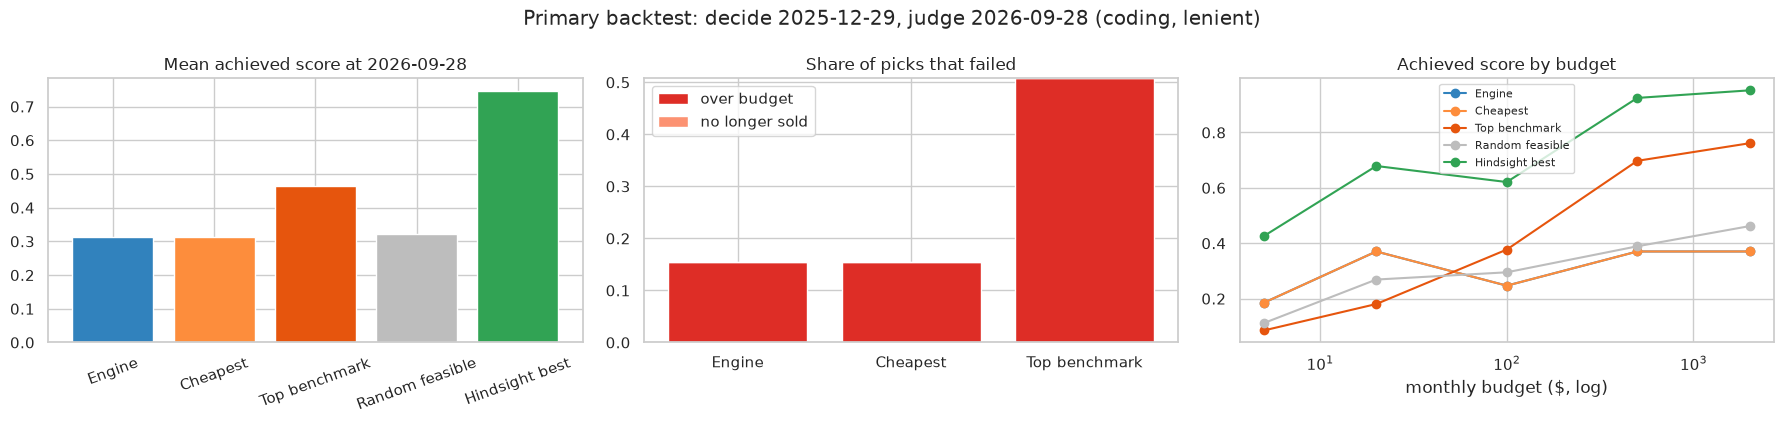

In [11]:
prim = bt[(bt.cutoff == PRIMARY["cutoff"]) & (bt["mode"] == PRIMARY["mode"]) & (bt.task == PRIMARY["task"])]
main = ["Engine", "Cheapest", "Top benchmark", "Random feasible", "Hindsight best"]
pal = dict(zip(main, ["#3182bd", "#fd8d3c", "#e6550d", "#bdbdbd", "#31a354"]))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
s = summary[key & summary.method.isin(main)]
ax[0].bar(s.method.astype(str), s.mean_achieved, color=[pal[m] for m in s.method.astype(str)])
ax[0].set_title("Mean achieved score at 2026-09-28"); ax[0].tick_params(axis="x", rotation=20)
sf = s[s.method.isin(["Engine", "Cheapest", "Top benchmark"])]
ax[1].bar(sf.method.astype(str), sf.over_budget, label="over budget", color="#de2d26")
ax[1].bar(sf.method.astype(str), sf.unavailable, bottom=sf.over_budget, label="no longer sold", color="#fc9272")
ax[1].set_title("Share of picks that failed"); ax[1].legend()
byb = prim[prim.method.isin(main)].groupby(["budget", "method"]).achieved.mean().unstack()
for m in main:
    ax[2].plot(byb.index, byb[m], marker="o", label=m, color=pal[m])
ax[2].set_xscale("log"); ax[2].set_xlabel("monthly budget ($, log)"); ax[2].set_title("Achieved score by budget")
ax[2].legend(fontsize=8)
plt.suptitle(f"Primary backtest: decide {PRIMARY['cutoff']}, judge {EVAL_WEEK} ({PRIMARY['task']}, {PRIMARY['mode']})")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq4_backtest_primary.png"), dpi=150); plt.show()

**Reading the result:**
- **Cheapest** picks the lowest-cost model, so it rarely fails on budget but may pick weak models.
- **Top benchmark** picks the strongest model but ignores the budget. It fails whenever that model is (or becomes) too expensive, mostly at small budgets (left side of the line plot).
- Compare the **engine** with both. The diagnostic below explains the pattern you see.
- **Regret** compares every method with the best decision possible in hindsight.

### 10a · Diagnostic: what does "value = score ÷ cost" actually reward?
If the engine's picks look like the cheapest rule's, the reason lies in the **scales**. Task scores live in **0–1**, while monthly costs span **several orders of magnitude**. Dividing by cost then lets the **cost dominate** the ranking. The check below compares, in the primary pool, (a) how far each quantity spreads and (b) how closely the value ranking follows the cost ranking (Spearman correlation; −1 = value order is exactly cheapest-first).

In [12]:
from scipy.stats import spearmanr
pc = candidates(PRIMARY["cutoff"], PRIMARY["task"], PRIMARY["mode"], trend_engine)
u = list(USAGE)[1]
val = pc.score / pc[u]
print(f"primary pool: {len(pc)} coding models at {PRIMARY['cutoff']}")
print(f"cost spread  : ${pc[u].min():.2f} … ${pc[u].max():,.0f}  (×{pc[u].max()/pc[u].min():,.0f})")
print(f"score spread : {pc.score.min():.2f} … {pc.score.max():.2f}")
print(f"Spearman(value rank, cost rank) = {spearmanr(val, pc[u]).correlation:+.2f} | "
      f"Spearman(value rank, score rank) = {spearmanr(val, pc.score).correlation:+.2f}")
same = (bt[(bt.method == "Engine")].set_index(["cutoff", "mode", "task", "usage", "budget", "req"]).pick ==
        bt[(bt.method == "Cheapest")].set_index(["cutoff", "mode", "task", "usage", "budget", "req"]).pick)
print("\nshare of scenarios where Engine picks exactly the Cheapest model:")
print(same.groupby(level=[0, 1, 2]).mean().round(2).unstack("task").to_string())
print("\nhow often each model is the engine's #1 pick (primary):")
print(prim[prim.method == "Engine"].pick.value_counts().head(5).to_string())

primary pool: 57 coding models at 2025-12-29
cost spread  : $3.24 … $3,600  (×1,111)
score spread : 0.00 … 1.00
Spearman(value rank, cost rank) = -0.74 | Spearman(value rank, score rank) = +0.18

share of scenarios where Engine picks exactly the Cheapest model:
task                coding  reasoning  vision
cutoff     mode                              
2025-12-29 lenient     1.0        NaN     NaN
           strict      1.0        NaN     NaN
2026-03-30 lenient     1.0        0.4     NaN
           strict      1.0        NaN     NaN
2026-06-29 lenient     1.0        0.3     0.4
           strict      1.0        0.3     0.4

how often each model is the engine's #1 pick (primary):
pick
alibaba/qwen3-32b    65


**Reading the result:** a strongly **negative** correlation between value and cost (and a weak one with score) means the value score is mostly a **price** ranking. Any model with a non-zero score and a rock-bottom price wins, and because the cheapest model fits almost every budget, the budget filter rarely matters. This is a property of the proposal's value formula, not a coding error. It is the main reason behind the H4 result below.

### 10b · All settings: secondary cutoffs, other tasks, strict mode
The same comparison for every cutoff × mode × task with at least 5 scenarios. These are **secondary**. They show whether the primary result generalises, but they do not decide H4.

Mean achieved score by setting:
method                        Engine  Engine, no trend  Engine, oracle trend  Score-first variant  Cheapest  Top benchmark  Random feasible  Hindsight best  n_scen
cutoff     mode    task                                                                                                                                            
2025-12-29 lenient coding      0.313             0.313                 0.313                0.565     0.313          0.465            0.323           0.746      65
           strict  coding      0.313             0.313                 0.313                0.649     0.313          0.513            0.334           0.730      65
2026-03-30 lenient coding      0.313             0.313                 0.313                0.740     0.313          0.769            0.339           0.804      65
                   reasoning   0.217             0.217                 0.217                0.423     0.082          0.254            0.273         

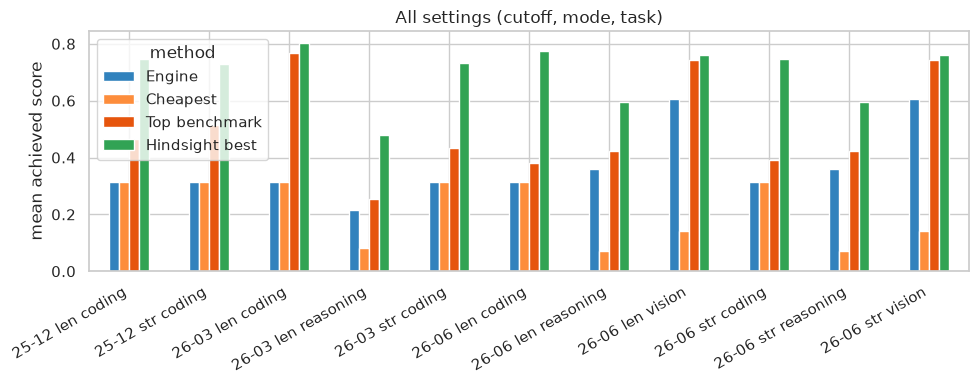

In [13]:
wide = summary.pivot_table(index=["cutoff", "mode", "task"], columns="method", values="mean_achieved",
                           observed=True)[[m for m in METHODS if m in summary.method.astype(str).unique()]]
wide["n_scen"] = summary[summary.method == "Engine"].set_index(["cutoff", "mode", "task"]).n
print("Mean achieved score by setting:"); print(wide[wide.n_scen >= 5].round(3).to_string())
cc = comp[comp.engine_vs.isin(["Cheapest", "Top benchmark"])].pivot_table(
    index=["cutoff", "mode", "task"], columns="engine_vs", values=["win", "loss", "p_value"])
print("\nEngine vs cheapest / top benchmark (win rate, loss rate, p):"); print(cc.round(3).to_string())

plt.figure(figsize=(10, 4))
w2 = wide[wide.n_scen >= 5][["Engine", "Cheapest", "Top benchmark", "Hindsight best"]]
w2.index = [f"{c[2:7]} {m[:3]} {t}" for c, m, t in w2.index]
w2.plot.bar(ax=plt.gca(), color=["#3182bd", "#fd8d3c", "#e6550d", "#31a354"])
plt.ylabel("mean achieved score"); plt.title("All settings (cutoff, mode, task)"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq4_backtest_all_settings.png"), dpi=150); plt.show()

### 10c · Did the future adjustment (step 5) help?
Compare the engine **with** the trend step, **without** it, and with the **oracle** trend. If even the oracle barely changes the outcome, then price trends hardly matter in this period, because prices were mostly flat. That would be a finding about the market, not a failure of RQ3.

In [14]:
tr = summary[summary.method.isin(["Engine, no trend", "Engine", "Engine, oracle trend"])].pivot_table(
    index=["cutoff", "mode", "task"], columns="method", values=["mean_achieved", "fail_rate"], observed=True)
print(tr.round(4).to_string())
changed = (bt.pivot_table(index=["cutoff", "mode", "task", "usage", "budget", "req"], columns="method",
                          values="pick", aggfunc="first"))
for m in ["Engine", "Engine, oracle trend"]:
    print(f"share of scenarios where '{m}' picks differently from 'Engine, no trend': "
          f"{(changed[m] != changed['Engine, no trend']).mean():.1%}")

                             fail_rate                                       mean_achieved                                      
method                          Engine Engine, no trend Engine, oracle trend        Engine Engine, no trend Engine, oracle trend
cutoff     mode    task                                                                                                         
2025-12-29 lenient coding       0.1538           0.1538               0.1538        0.3134           0.3134               0.3134
           strict  coding       0.1538           0.1538               0.1538        0.3134           0.3134               0.3134
2026-03-30 lenient coding       0.1538           0.1538               0.1538        0.3134           0.3134               0.3134
                   reasoning    0.0000           0.0000               0.0000        0.2171           0.2171               0.2171
           strict  coding       0.1538           0.1538               0.1538        0.3134       

## Step 11 · Save results
- `rq4_backtest_results.csv`: one row per cutoff × mode × scenario × method (pick, achieved score, failure flags, regret).
- `rq4_summary.csv`: the aggregated table from Step 10.
- `rq4_mapping.csv`: the model ↔ price-history link table from Step 2 (match audit).
- Figures go to `reports/figures/rq4_*.png`.

In [15]:
bt.to_csv(os.path.join(OUT_DIR, "rq4_backtest_results.csv"), index=False)
summary.to_csv(os.path.join(OUT_DIR, "rq4_summary.csv"), index=False)
mapping.to_csv(os.path.join(OUT_DIR, "rq4_mapping.csv"), index=False)
print("saved rq4_backtest_results.csv", bt.shape, "| rq4_summary.csv", summary.shape,
      "| rq4_mapping.csv", mapping.shape)
if IN_COLAB:
    for f in ["rq4_backtest_results.csv", "rq4_summary.csv", "rq4_mapping.csv"]:
        files.download(f)

saved rq4_backtest_results.csv (4664, 15) | rq4_summary.csv (88, 10) | rq4_mapping.csv (147, 6)


## Step 12 · Conclusion: H4 verdict computed from the numbers
Rule from Step 1: in the **primary setting**, the engine's mean achieved score must be higher than **both** "cheapest" and "top benchmark", with Wilcoxon p < 0.05 for each comparison.

In [16]:
def beats(other):
    r = comp[ckey & (comp.engine_vs == other)].iloc[0]
    return bool(r.mean_diff > 0 and r.p_value < 0.05), r

ok_c, rc = beats("Cheapest"); ok_t, rt = beats("Top benchmark")
h4 = "SUPPORTED" if (ok_c and ok_t) else "PARTIAL" if (ok_c or ok_t) else "NOT supported"
ps = summary[key].set_index("method")
print(f"Trend source: {TREND_SOURCE}")
print(f"Primary: decide {PRIMARY['cutoff']}, judge {EVAL_WEEK}, {PRIMARY['task']}, {PRIMARY['mode']} — "
      f"{int(ps.loc['Engine','n'])} scenarios")
for m in ["Engine", "Cheapest", "Top benchmark", "Random feasible", "Score-first variant", "Hindsight best"]:
    print(f"  {m:20s} mean achieved {ps.loc[m,'mean_achieved']:.3f} | failed {ps.loc[m,'fail_rate']:.1%}"
          f" | regret {ps.loc[m,'mean_regret']:.3f}")
print(f"\nEngine vs Cheapest:      diff {rc.mean_diff:+.3f}, win {rc.win:.0%} / tie {rc.tie:.0%} / loss {rc.loss:.0%}, p = {rc.p_value:.4g}")
print(f"Engine vs Top benchmark: diff {rt.mean_diff:+.3f}, win {rt.win:.0%} / tie {rt.tie:.0%} / loss {rt.loss:.0%}, p = {rt.p_value:.4g}")
print(f"\nH4 (engine gives better value than cheapest AND top-benchmark): {h4}")

Trend source: PLACEHOLDER momentum rule (RQ3 not available yet)
Primary: decide 2025-12-29, judge 2026-09-28, coding, lenient — 65 scenarios
  Engine               mean achieved 0.313 | failed 15.4% | regret 0.433
  Cheapest             mean achieved 0.313 | failed 15.4% | regret 0.433
  Top benchmark        mean achieved 0.465 | failed 50.8% | regret 0.282
  Random feasible      mean achieved 0.323 | failed 21.0% | regret 0.423
  Score-first variant  mean achieved 0.565 | failed 38.5% | regret 0.181
  Hindsight best       mean achieved 0.746 | failed nan% | regret 0.000

Engine vs Cheapest:      diff +0.000, win 0% / tie 100% / loss 0%, p = nan
Engine vs Top benchmark: diff -0.151, win 35% / tie 15% / loss 49%, p = 2.778e-05

H4 (engine gives better value than cheapest AND top-benchmark): NOT supported


### Answer to RQ4
*(Filled in from the executed results; see the cell outputs above.)*

**Not with the algorithm as proposed. H4 is NOT supported.** The engine never beat "pick the top benchmark" on average and, for coding, was identical to "pick the cheapest".

**Primary test** (decide 29 Dec 2025, judge 28 Sep 2026, coding, 65 scenarios):

| Method | Mean achieved score | Picks that failed by Sep 2026 |
|---|---|---|
| Engine (proposal) | 0.31 | 15% |
| Cheapest | 0.31 | 15% |
| Top benchmark | 0.47 | 51% (over budget) |
| Random feasible | 0.32 | 21% |
| *Score-first variant* | *0.57* | *38%* |
| Hindsight best | 0.75 | n/a |

- The engine chose **exactly the cheapest model in all 65 scenarios** (Qwen3-32B at $0.027 per 1M tokens), so the two tie everywhere.
- Against top benchmark it **lost** more scenarios than it won (49% vs 35%, Wilcoxon p < 0.001, in the wrong direction for H4). Top benchmark fails on budget half of the time, but when its pick fits the budget it gives a much stronger model.

**Why:** the value score = task score ÷ cost is **dominated by cost** (Step 10a). Scores span 0–1 while costs span orders of magnitude, so value-ranking becomes "cheapest model with any score", and the budget barely matters. The "now" demo shows the same thing: the $5,000/month enterprise persona is offered GLM-5.3-Flash (score 0.62, $100) ahead of GLM-5.3 (score 0.91, $850), which is well within its budget.

**Secondary settings** (2026 cutoffs, strict mode, reasoning, vision): the pattern holds. For coding the engine equals cheapest at every cutoff. For reasoning and vision it beats cheapest but stays **below top benchmark** in mean achieved score in every setting.

**The future adjustment (step 5) changed 0% of picks**, even with the *oracle* trend. A ×1.25 / ×0.75 nudge cannot overturn value ratios that differ by orders of magnitude, and most prices stayed flat. RQ3 can only matter once the ranking is no longer cost-dominated.

**Exploratory, not H4 evidence:** a **budget-aware "score-first" rule** (best task score that fits the budget) scored 0.57 in the primary test, above both cheapest and top benchmark, and above top benchmark in 8 of 11 settings. Its weak point is budget failures (38%), because it picks models close to the budget limit, which is exactly where a price-trend signal and a safety margin could help. This suggests a revised algorithm (rank by score within budget, keep a headroom margin, use RQ3 trends to avoid rising models). It must be **tested as a new, pre-registered hypothesis**, not claimed from this run.

### Limitations
- **Small, overlapping scenario set.** The pool at the primary cutoff is a few dozen coding models, and neighbouring scenarios often share the same pick, so p-values are optimistic. Win/tie/loss rates are the more robust summary.
- **Placeholder trend input** until RQ3 is built. The oracle row shows the most a perfect trend classifier could add.
- **Lenient scores use benchmark results published after the cutoff**, which assumes model ability is fixed. Strict mode avoids this but has far fewer candidates.
- **Mostly flat prices** in the evaluation period mean failures come mainly from models leaving the market and from naive budget-ignoring picks, not from price rises.
- **Tiers** are RQ1 labels fitted on all data and are shown only as a description. They do not affect any pick.
- **Price = cheapest provider**, while RQ1 tiered on the median price. Free tiers are excluded. Quantised or renamed variants (e.g. `…-fp8`) are not linked, so some cheap offers are missed. This is conservative.
- **The score-first finding is exploratory.** It was not the pre-registered engine, so it needs confirmation on new data (e.g. a later cutoff, or once RQ3 trends exist).